# Домашнее задание. Предсказание цены подержанного автомобиля

Это домашнее задание к модулю **«Задача регрессии»**.

Весь модуль мы обсуждали, как предсказать цену автомобиля по его характеристикам. Теперь сделаем это сами — но не на десяти автомобилях из таблицы в уроках, а на трёх тысячах объявлений.

**Как работать с ноутбуком:**

1. Откройте ноутбук в Google Colab.
2. Выполняйте ячейки по порядку сверху вниз.
3. Там, где написано `# ваш код здесь`, допишите свой код.
4. Числа и выводы, которые у вас получатся, впишите в квизы урока «Домашнее задание» на Stepik.

Ничего скачивать и устанавливать не нужно: данные создаются прямо в ноутбуке.

## Готовим данные

Сначала подключим библиотеки, которые понадобятся дальше.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

Теперь создадим таблицу объявлений. Разбираться в коде этой ячейки не нужно — просто запустите её.

Число `RANDOM_STATE` фиксирует случайность: благодаря ему таблица получится одинаковой у всех, кто выполняет это задание. Поэтому менять его не нужно, иначе ваши ответы не совпадут с правильными.

In [7]:
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)
n = 3000

age = rng.integers(1, 16, n)
km_per_year = rng.normal(14, 4, n).clip(5, 25)
mileage = (age * km_per_year).round(0)
engine = rng.choice([1.2, 1.4, 1.6, 1.8, 2.0, 2.5, 3.0], n, p=[0.10, 0.18, 0.22, 0.20, 0.15, 0.10, 0.05])
power = (engine * 55 + rng.normal(0, 12, n)).round(0).clip(70, 300)
noise = rng.normal(0, 150, n)
price = (1500 - 3 * mileage - 30 * age + 3.5 * power + 50 * engine + noise).round(0)

cars = pd.DataFrame({
    "mileage": mileage,
    "age": age,
    "power": power,
    "engine": engine,
    "price": price,
})

cars.head()

,mileage,age,power,engine,price
0,36.0,2,98.0,1.8,1530.0
1,133.0,12,100.0,2.0,1107.0
2,106.0,10,70.0,1.2,1480.0
3,111.0,7,94.0,1.8,1661.0
4,126.0,7,112.0,1.8,1326.0


Столбцы таблицы:

- `mileage` — пробег, тыс. км;
- `age` — возраст автомобиля, лет;
- `power` — мощность двигателя, л. с.;
- `engine` — объём двигателя, л;
- `price` — цена, тыс. руб. Это наша целевая переменная.

## Задание 1

Выясните, сколько строк и столбцов в таблице `cars`.

Сколько в ней признаков? Помните, что целевая переменная признаком не является.

In [9]:
cars.shape

(3000, 5)

## Задание 2

Постройте диаграмму рассеяния: по горизонтали — пробег (`mileage`), по вертикали — цена (`price`).

Какая зависимость видна на графике — прямая или обратная?

Подсказка: диаграмма рассеяния строится функцией `plt.scatter(x, y)`.

<function matplotlib.pyplot.show(close=None, block=None)>

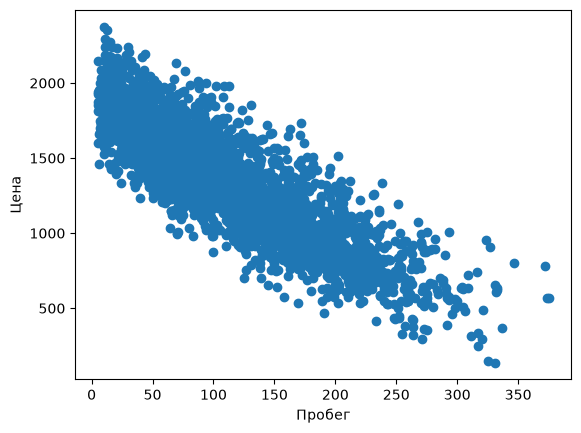

In [10]:
plt.scatter(cars['mileage'], cars['price'])
plt.xlabel('Пробег')
plt.ylabel('Цена')
plt.show

## Разделяем данные на обучающую и тестовую части

Прежде чем обучать модель, отложим часть объявлений в сторону. На них модель учиться не будет — они понадобятся, чтобы честно проверить её качество.

Разбиение делает функция `train_test_split`. Параметр `test_size=0.25` означает, что в тестовую часть уйдёт 25% объявлений, а остальные 75% останутся для обучения. Эта ячейка уже написана, просто запустите её.

In [11]:
X = cars[["mileage", "age", "power", "engine"]]
y = cars["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

## Задание 3

Сколько объявлений попало в тестовую часть `X_test`?

In [12]:
X_test.shape

(750, 4)

## Задание 4. Базовая модель

Начнём, как и в уроках, с базовой модели: она предсказывает всем автомобилям одну и ту же цену — среднюю.

Важная деталь: среднее нужно считать **по обучающей выборке** (`y_train`). Тестовые данные модель видеть не должна даже так.

Посчитайте MAE базовой модели на тестовых данных и округлите результат до целого.

Подсказка: массив из одинаковых чисел нужной длины создаётся так — `np.full(len(y_test), значение)`. Метрика считается функцией `mean_absolute_error(правильные_ответы, предсказания)`.

In [18]:
mean_base = np.full(len(y_test), y_test.mean())
MAE = mean_absolute_error(y_test, mean_base)
print(f'{MAE:.0f}')

306


## Задание 5. Линейная регрессия

Теперь обучим настоящую модель.

1. Создайте модель: `model = LinearRegression()`.
2. Обучите её на обучающих данных: `model.fit(X_train, y_train)`.
3. Сделайте предсказания для тестовых данных: `model.predict(X_test)`.
4. Посчитайте на тестовых данных метрики MAE и R².

MAE округлите до целого, R² — до сотых.

In [20]:
from sklearn.metrics import r2_score

model = LinearRegression()
model.fit(X_train, y_train)
y_prediction = model.predict(X_test)
MAE_model = mean_absolute_error(y_test, y_prediction)
R_square = r2_score(y_test, y_prediction)
print(f'{MAE_model:.0f}', f'{R_square:.2f}')

126 0.82


Сравните полученные числа с базовой моделью из задания 4. Насколько сильно линейная регрессия её обошла?

Из любопытства посчитайте MAE ещё и на **обучающих** данных — тех самых, которые модель уже видела. Запустите ячейку ниже.

In [21]:
print("MAE на обучающих данных:", round(mean_absolute_error(y_train, model.predict(X_train)), 2))
print("MAE на тестовых данных: ", round(mean_absolute_error(y_test, model.predict(X_test)), 2))

MAE на обучающих данных: 116.67
MAE на тестовых данных:  126.02


На обучающих данных ошибка получилась меньше — так бывает почти всегда. Модель подбирала коэффициенты именно под них, поэтому на знакомых примерах ей проще. Честной оценкой качества считается вторая цифра, посчитанная на данных, которых модель не видела.

## Задание 6. Читаем коэффициенты

Обученная модель хранит подобранные коэффициенты в `model.coef_`, а свободный член — в `model.intercept_`.

Выведите коэффициенты рядом с названиями признаков и посмотрите, какой знак получился у каждого из них.

Подсказка: удобно сделать так — `pd.Series(model.coef_, index=X.columns)`.

In [22]:
pd.Series(model.coef_, index=X.columns)

mileage    -3.105889
age       -28.502893
power       3.513994
engine     46.722157
dtype: float64

Обратите внимание, что знаки коэффициентов совпали со здравым смыслом: пробег и возраст цену снижают, а мощность и объём двигателя — повышают.

На этом задание закончено. Возвращайтесь к квизам на Stepik и впишите туда полученные числа!